#1. Dane

In [ ]:
# =========================
# IMPORTY
# =========================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout

from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# =========================
# Globalne ustawienia
# =========================

HYPERPARAMS = {
    "epochs": 20,
    "window": 30,
    "patience": 5,
    "batch_size": 8,
}

In [ ]:
# =========================
# WCZYTANIE DANYCH
# =========================

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/MIW5/stock_data.csv")

print("Raw data shape:", df.shape)
display(df.head())

# Sortowanie po dacie
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date")

display(df.head())


Raw data shape: (7912, 6)


,Date,Open,High,Low,Close,Volume
0,1994-08-02,7.81771,7.81771,7.81771,7.81771,367585.965096
1,1994-08-03,8.58656,8.58656,8.58656,8.58656,344379.468509
2,1994-08-04,9.43808,9.43808,9.43808,9.43808,376470.208699
3,1994-08-08,8.58656,8.58656,8.58656,8.58656,279170.705645
4,1994-08-09,10.13470,10.13470,10.13470,10.13470,143430.456748


,Date,Open,High,Low,Close,Volume
0,1994-08-02,7.81771,7.81771,7.81771,7.81771,367585.965096
1,1994-08-03,8.58656,8.58656,8.58656,8.58656,344379.468509
2,1994-08-04,9.43808,9.43808,9.43808,9.43808,376470.208699
3,1994-08-08,8.58656,8.58656,8.58656,8.58656,279170.705645
4,1994-08-09,10.13470,10.13470,10.13470,10.13470,143430.456748


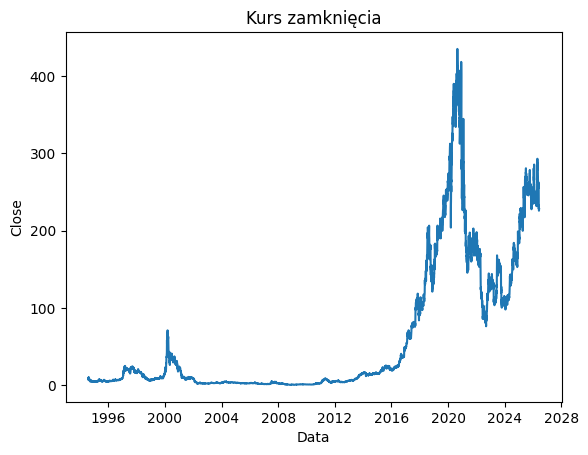

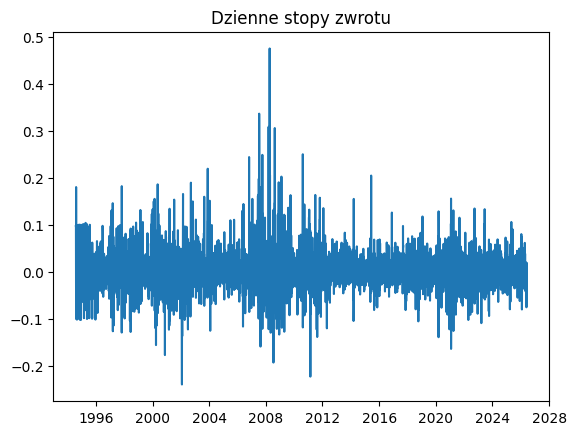

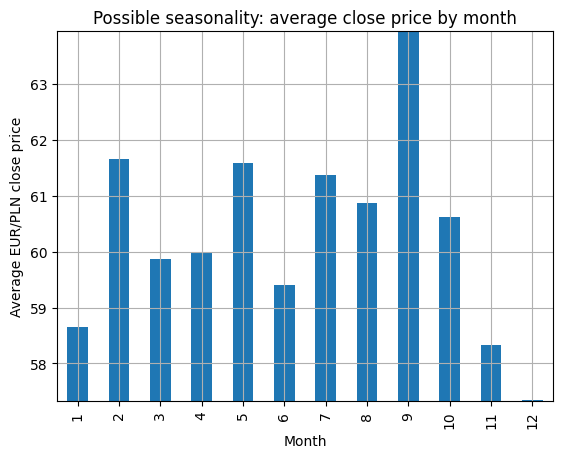

Monthly standard deviation:


,Standard deviation
Month,
1,85.064165
2,87.871448
3,81.524930
4,86.832111
5,90.242397
6,90.828773
7,93.616057
8,94.692373
9,97.187914


Highest monthly average: month 9, value 63.9322
Lowest monthly average: month 12, value 57.3378
Difference between highest and lowest monthly average: 6.5944


In [ ]:
# ============================================================
# ANALIZA WSTĘPNA
# ============================================================

# =========================
# TREND
# =========================

plt.figure()
plt.plot(df["Date"], df["Close"])
plt.title("Kurs zamknięcia")
plt.xlabel("Data")
plt.ylabel("Close")
plt.show()

# =========================
# ZMIENNOŚĆ
# =========================

df["Return"] = df["Close"].pct_change()

plt.figure()
plt.plot(df["Date"], df["Return"])
plt.title("Dzienne stopy zwrotu")
plt.show()

# =========================
# SEZONOWOŚĆ
# =========================

df["Month"] = df["Date"].dt.month

monthly_mean = df.groupby("Month")["Close"].mean()
monthly_std = df.groupby("Month")["Close"].std()

plt.figure()
monthly_mean.plot(kind="bar")
plt.title("Possible seasonality: average close price by month")
plt.xlabel("Month")
plt.ylabel("Average EUR/PLN close price")
plt.ylim(monthly_mean.min() - 0.01, monthly_mean.max() + 0.01)
plt.grid(True)
plt.show()

print("Monthly standard deviation:")
display(monthly_std.to_frame(name="Standard deviation"))

max_month = monthly_mean.idxmax()
min_month = monthly_mean.idxmin()
difference = monthly_mean.max() - monthly_mean.min()

print(f"Highest monthly average: month {max_month}, value {monthly_mean.max():.4f}")
print(f"Lowest monthly average: month {min_month}, value {monthly_mean.min():.4f}")
print(f"Difference between highest and lowest monthly average: {difference:.4f}")

Train: 1994-08-02 -> 2013-09-27 (4747, 8)
Validation: 2013-09-30 -> 2020-02-06 (1582, 8)
Test: 2020-02-07 -> 2026-06-05 (1583, 8)


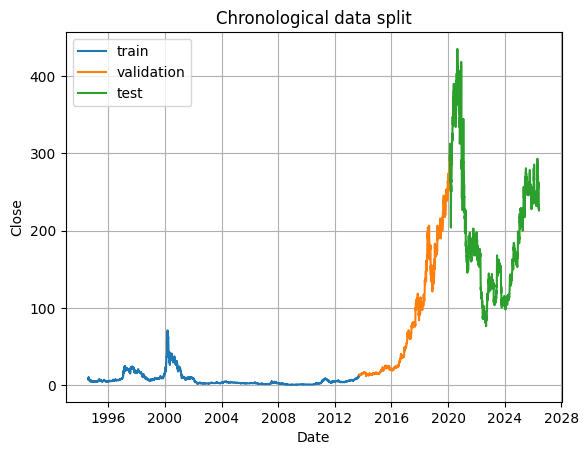

In [ ]:
# ============================================================
# PODZIAŁ DANYCH
# ============================================================

n = len(df)

train_end = int(n * 0.6)
val_end = int(n * 0.8)

df_train = df.iloc[:train_end].copy()
df_val = df.iloc[train_end:val_end].copy()
df_test = df.iloc[val_end:].copy()

# Pokazanie podziału danycg

print("Train:", df_train["Date"].min().date(), "->", df_train["Date"].max().date(), df_train.shape)
print("Validation:", df_val["Date"].min().date(), "->", df_val["Date"].max().date(), df_val.shape)
print("Test:", df_test["Date"].min().date(), "->", df_test["Date"].max().date(), df_test.shape)

plt.figure()
plt.plot(df_train["Date"], df_train["Close"], label="train")
plt.plot(df_val["Date"], df_val["Close"], label="validation")
plt.plot(df_test["Date"], df_test["Close"], label="test")
plt.title("Chronological data split")
plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# NORMALIZACJA
# ============================================================

scaler_y = MinMaxScaler()

train_y = df_train[["Close"]].values
val_y = df_val[["Close"]].values
test_y = df_test[["Close"]].values

train_scaled = scaler_y.fit_transform(train_y).flatten()
val_scaled = scaler_y.transform(val_y).flatten()
test_scaled = scaler_y.transform(test_y).flatten()

y_scaled_all = np.concatenate([train_scaled, val_scaled, test_scaled])

print("Training target range after normalization:")
print("min =", train_scaled.min(), "max =", train_scaled.max())


Training target range after normalization:
min = 0.0 max = 1.0


#2. Prosty model rekurencyjny RNN

In [ ]:
# ============================================================
# TWORZENIE SEKWENCJI
# ============================================================

def create_sequences(series, window):
    X, y = [], []
    for i in range(window, len(series)):
        X.append(series[i - window:i])
        y.append(series[i])
    X = np.array(X)
    y = np.array(y)
    X = X.reshape((X.shape[0], X.shape[1], 1))
    return X, y

In [ ]:
def split_sequences_by_target_index(X_seq, y_seq, target_indices, train_end_idx, val_end_idx):
    """Split sequences according to the time index of their target value."""
    train_mask = target_indices < train_end_idx
    val_mask = (target_indices >= train_end_idx) & (target_indices < val_end_idx)
    test_mask = target_indices >= val_end_idx

    return (
        X_seq[train_mask], y_seq[train_mask],
        X_seq[val_mask], y_seq[val_mask],
        X_seq[test_mask], y_seq[test_mask],
        test_mask,
    )

In [ ]:
WINDOW = HYPERPARAMS["window"]

X_seq, y_seq = create_sequences(y_scaled_all, WINDOW)
target_indices_seq = np.arange(WINDOW, len(y_scaled_all))

(
    X_train_seq, y_train_seq,
    X_val_seq, y_val_seq,
    X_test_seq, y_test_seq,
    test_mask_seq,
) = split_sequences_by_target_index(
    X_seq,
    y_seq,
    target_indices_seq,
    train_end,
    val_end,
)

print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)
print("X_val_seq:", X_val_seq.shape)
print("X_test_seq:", X_test_seq.shape)

X_train_seq: (4717, 30, 1)
y_train_seq: (4717,)
X_val_seq: (1582, 30, 1)
X_test_seq: (1583, 30, 1)


In [ ]:
def evaluate_regression_model(model, X_test, y_test_scaled, scaler, model_name):
    """Predict, inverse-transform, calculate MSE and MAE, and return results."""
    pred_scaled = model.predict(X_test).flatten()

    pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    true = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).flatten()

    mse = mean_squared_error(true, pred)
    mae = mean_absolute_error(true, pred)

    print(f"{model_name} test MSE: {mse:.8f}")
    print(f"{model_name} test MAE: {mae:.8f}")

    return true, pred, mse, mae


def plot_training_history(history, title):
    plt.figure()
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_predictions(dates, true, pred, title, pred_label):
    plt.figure()
    plt.plot(dates, true, label="Actual")
    plt.plot(dates, pred, label=pred_label)
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("EUR/PLN")
    plt.legend()
    plt.grid(True)
    plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_6 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 0.0015 - val_loss: 0.5373
Epoch 2/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 5.5181e-04 - val_loss: 0.2867
Epoch 3/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.9436e-04 - val_loss: 0.1443
Epoch 4/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 3.4083e-04 - val_loss: 0.1215
Epoch 5/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.3592e-04 - val_loss: 0.1269
Epoch 6/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.4915e-04 - val_loss: 0.0429
Epoch 7/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.1399e-04 - val_loss: 0.0637
Epoch 8/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2.8782e-04 - val_loss: 0.0784
Epoch 9/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 2.5793e-04 - val_loss: 0.0322
Epoch 10/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 2.7295e-04 - val_loss: 0.0409
Epoch 11/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.1215e-04 - val_loss: 0.0461
Epoch 12/20


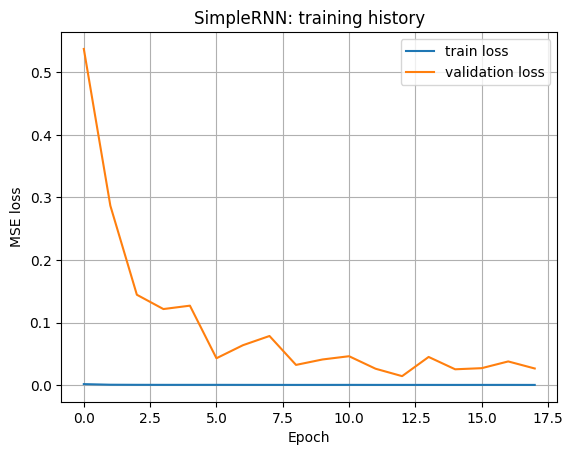

In [ ]:
# ============================================================
# SIMPLE RNN
# ============================================================

simple_rnn_model = Sequential([
    SimpleRNN(32, activation="tanh", input_shape=(WINDOW, 1)),
    Dropout(0.2),
    Dense(1),
])

simple_rnn_model.compile(
    optimizer="adam",
    loss="mse"
)

simple_rnn_model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=HYPERPARAMS["patience"],
    restore_best_weights=True,
)

history_simple_rnn = simple_rnn_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq,y_val_seq),
    epochs=HYPERPARAMS["epochs"],
    batch_size=HYPERPARAMS["batch_size"],
    callbacks=[early_stop],
    verbose=1
)

plot_training_history(history_simple_rnn, "SimpleRNN: training history")

50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
SimpleRNN test MSE: 1027.22317008
SimpleRNN test MAE: 19.58913337


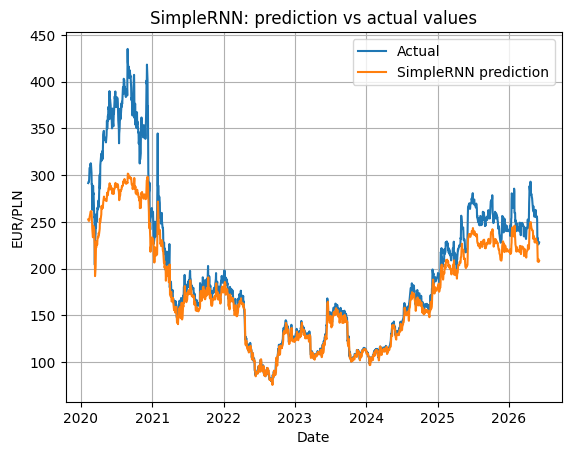

In [ ]:
simple_rnn_true, simple_rnn_pred, simple_rnn_mse, simple_rnn_mae = evaluate_regression_model(
    simple_rnn_model,
    X_test_seq,
    y_test_seq,
    scaler_y,
    "SimpleRNN",
)

simple_rnn_test_dates = df["Date"].iloc[target_indices_seq[test_mask_seq]].values

plot_predictions(
    simple_rnn_test_dates,
    simple_rnn_true,
    simple_rnn_pred,
    "SimpleRNN: prediction vs actual values",
    "SimpleRNN prediction",
)

#3. Model rekurencyjny z komórkami pamięci: LSTM lub GRU

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.0019 - val_loss: 0.3560
Epoch 2/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 5.0227e-04 - val_loss: 0.1869
Epoch 3/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.9398e-04 - val_loss: 0.1329
Epoch 4/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.5806e-04 - val_loss: 0.0593
Epoch 5/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 3.5180e-04 - val_loss: 0.0615
Epoch 6/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 3.2043e-04 - val_loss: 0.0665
Epoch 7/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2.9977e-04 - val_loss: 0.0787
Epoch 8/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 3.1101e-04 - val_loss: 0.0416
Epoch 9/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 2.6133e-04 - val_loss: 0.0573
Epoch 10/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2.6066e-04 - val_loss: 0.0419
Epoch 11/20
590/590 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2.4139e-04 - val_loss: 0.0355
Epoch 12/20


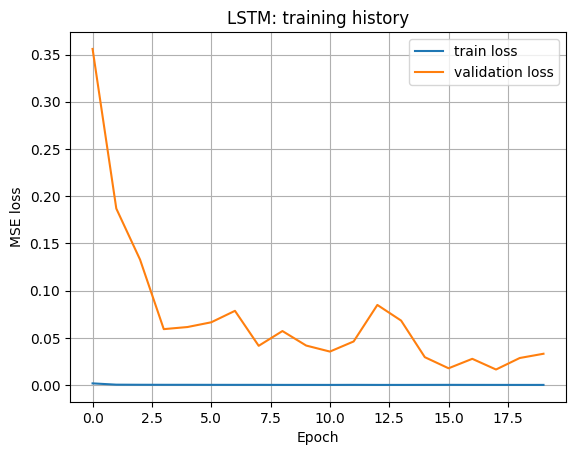

In [ ]:
# ============================================================
# LSTM
# ============================================================

lstm_model = Sequential([
    LSTM(32, activation="tanh", input_shape=(WINDOW, 1)),
    Dropout(0.2),
    Dense(1),
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=HYPERPARAMS["patience"],
    restore_best_weights=True,
)

history_lstm = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=HYPERPARAMS["epochs"],
    batch_size=HYPERPARAMS["batch_size"],
    callbacks=[early_stop],
    verbose=1,
)

plot_training_history(history_lstm, "LSTM: training history")

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
LSTM 1-feature test MSE: 809.51160873
LSTM 1-feature test MAE: 19.10400835


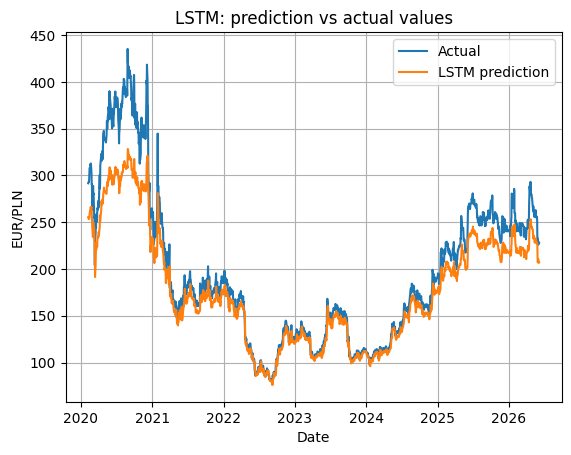

In [ ]:
lstm_true, lstm_pred, lstm_mse, lstm_mae = evaluate_regression_model(
    lstm_model,
    X_test_seq,
    y_test_seq,
    scaler_y,
    "LSTM 1-feature",
)

lstm_test_dates = df["Date"].iloc[target_indices_seq[test_mask_seq]].values

plot_predictions(
    lstm_test_dates,
    lstm_true,
    lstm_pred,
    "LSTM: prediction vs actual values",
    "LSTM prediction",
)

#Porownanie

,Model,MSE,MAE
0,SimpleRNN,1027.223170,19.589133
1,LSTM 1-feature,809.511609,19.104008


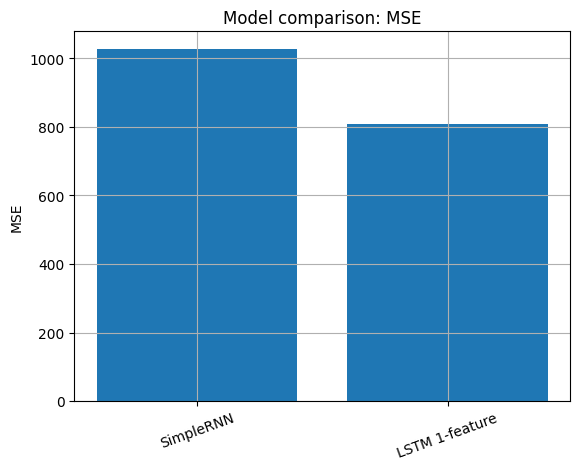

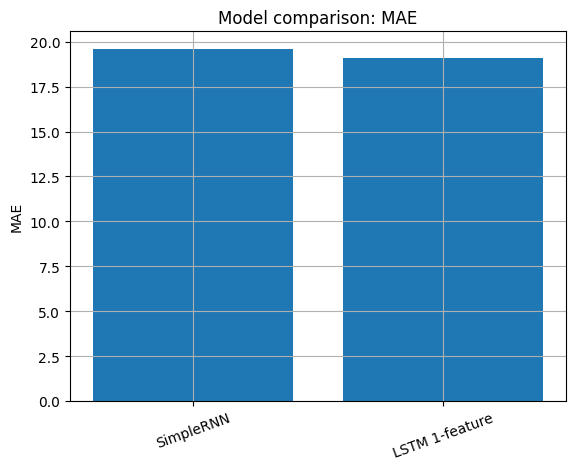

In [ ]:
# ============================================================
# PORÓWNANIE MODELI
# ============================================================
results = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "MSE": simple_rnn_mse,
        "MAE": simple_rnn_mae,
    },
    {
        "Model": "LSTM 1-feature",
        "MSE": lstm_mse,
        "MAE": lstm_mae,
    },
])

display(results)

plt.figure()
plt.bar(results["Model"], results["MSE"])
plt.title("Model comparison: MSE")
plt.ylabel("MSE")
plt.xticks(rotation=20)
plt.grid(True)
plt.show()

plt.figure()
plt.bar(results["Model"], results["MAE"])
plt.title("Model comparison: MAE")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.grid(True)
plt.show()

#4. Dane dodatkowe

In [ ]:
# ============================================================
# LSTM Z DODATKOWYMI CECHAMI
# ============================================================

df_features = df.copy()

# Create additional features
df["Range"] = df["High"] - df["Low"]

# Daily price difference - Return(t) = Close(t) - Close(t-1)
df["Return"] = df["Close"].diff()

# 20-day moving average
df["MA_20"] = df["Close"].rolling(window=20).mean()

# Difference between the current Close price and the 20-day moving average
df["Trend_20"] = df["Close"] - df["MA_20"]

# Remove rows with missing values created by diff() and rolling()
df = df.dropna().reset_index(drop=True)

feature_cols = [
    "Close",
    "Range",
    "Return",
    "MA_20",
    "Trend_20",
]

target_col = "Close"

# Corrected: Update df_features to include the newly created columns
df_features = df.copy()

print("Selected features:", feature_cols)
print("Number of features:", len(feature_cols))
display(df_features[["Date"] + feature_cols].head())


Selected features: ['Close', 'Range', 'Return', 'MA_20', 'Trend_20']
Number of features: 5


,Date,Close,Range,Return,MA_20,Trend_20
0,1994-09-06,6.67845,0.0,-0.75019,8.784411,-2.105961
1,1994-09-07,6.02075,0.0,-0.65770,8.694563,-2.673813
2,1994-09-08,6.59509,0.0,0.57434,8.594990,-1.999900
3,1994-09-12,7.23424,0.0,0.63915,8.484797,-1.250557
4,1994-09-13,6.52097,0.0,-0.71327,8.381518,-1.860548


In [ ]:
# ============================================================
# SEKWENCJE WIELOWYMIAROWE
# ============================================================

n_feat = len(df_features)
train_end_feat = int(0.60 * n_feat)
val_end_feat = int(0.80 * n_feat)

df_feat_train = df_features.iloc[:train_end_feat].copy()
df_feat_val = df_features.iloc[train_end_feat:val_end_feat].copy()
df_feat_test = df_features.iloc[val_end_feat:].copy()

scaler_X = MinMaxScaler()
scaler_y_feat = MinMaxScaler()

X_train_feat_raw = df_feat_train[feature_cols].values
X_val_feat_raw = df_feat_val[feature_cols].values
X_test_feat_raw = df_feat_test[feature_cols].values

y_train_feat_raw = df_feat_train[[target_col]].values
y_val_feat_raw = df_feat_val[[target_col]].values
y_test_feat_raw = df_feat_test[[target_col]].values

X_train_feat_scaled = scaler_X.fit_transform(X_train_feat_raw)
X_val_feat_scaled = scaler_X.transform(X_val_feat_raw)
X_test_feat_scaled = scaler_X.transform(X_test_feat_raw)

y_train_feat_scaled = scaler_y_feat.fit_transform(y_train_feat_raw).flatten()
y_val_feat_scaled = scaler_y_feat.transform(y_val_feat_raw).flatten()
y_test_feat_scaled = scaler_y_feat.transform(y_test_feat_raw).flatten()

X_feat_scaled_all = np.concatenate([X_train_feat_scaled, X_val_feat_scaled, X_test_feat_scaled])
y_feat_scaled_all = np.concatenate([y_train_feat_scaled, y_val_feat_scaled, y_test_feat_scaled])

print("X_feat_scaled_all:", X_feat_scaled_all.shape)
print("y_feat_scaled_all:", y_feat_scaled_all.shape)


X_feat_scaled_all: (7893, 5)
y_feat_scaled_all: (7893,)


In [ ]:
def create_sequences_multifeature(X_data, y_data, window):
    """Create multi-feature sequences for LSTM."""
    X_seq, y_seq = [], []
    for i in range(window, len(X_data)):
        X_seq.append(X_data[i - window:i, :])
        y_seq.append(y_data[i])
    return np.array(X_seq), np.array(y_seq)


WINDOW_FEATURES = HYPERPARAMS["window"]

X_multi, y_multi = create_sequences_multifeature(
    X_feat_scaled_all,
    y_feat_scaled_all,
    WINDOW_FEATURES,
)

target_indices_multi = np.arange(WINDOW_FEATURES, len(y_feat_scaled_all))

train_end_idx_feat = len(y_train_feat_scaled)
val_end_idx_feat = len(y_train_feat_scaled) + len(y_val_feat_scaled)

train_mask_multi = target_indices_multi < train_end_idx_feat
val_mask_multi = (target_indices_multi >= train_end_idx_feat) & (target_indices_multi < val_end_idx_feat)
test_mask_multi = target_indices_multi >= val_end_idx_feat

X_train_multi, y_train_multi = X_multi[train_mask_multi], y_multi[train_mask_multi]
X_val_multi, y_val_multi = X_multi[val_mask_multi], y_multi[val_mask_multi]
X_test_multi, y_test_multi = X_multi[test_mask_multi], y_multi[test_mask_multi]

print("X_train_multi:", X_train_multi.shape)
print("y_train_multi:", y_train_multi.shape)
print("X_val_multi:", X_val_multi.shape)
print("X_test_multi:", X_test_multi.shape)


X_train_multi: (4705, 30, 5)
y_train_multi: (4705,)
X_val_multi: (1579, 30, 5)
X_test_multi: (1579, 30, 5)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0023 - val_loss: 0.5849
Epoch 2/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 6.7431e-04 - val_loss: 0.6086
Epoch 3/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 4.5621e-04 - val_loss: 0.5489
Epoch 4/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 4.4028e-04 - val_loss: 0.3991
Epoch 5/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 3.3735e-04 - val_loss: 0.3337
Epoch 6/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 3.1939e-04 - val_loss: 0.3776
Epoch 7/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 2.9773e-04 - val_loss: 0.2576
Epoch 8/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 3.0276e-04 - val_loss: 0.1733
Epoch 9/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2.9034e-04 - val_loss: 0.2390
Epoch 10/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 2.6252e-04 - val_loss: 0.1480
Epoch 11/20
589/589 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2.4640e-04 - val_loss: 0.1651
Epoch 12

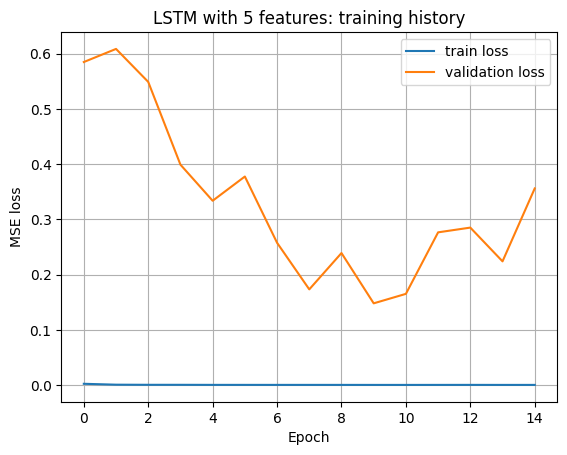

In [ ]:
# ============================================================
# LSTM MULTIVARIATE
# ============================================================

multi_lstm_model = Sequential([
    LSTM(32, activation="tanh", input_shape=(WINDOW_FEATURES, len(feature_cols))),
    Dropout(0.2),
    Dense(1),
])

multi_lstm_model.compile(
    optimizer="adam",
    loss="mse",
)

multi_lstm_model.summary()

early_stop_multi = EarlyStopping(
    monitor="val_loss",
    patience=HYPERPARAMS["patience"],
    restore_best_weights=True,
)

history_multi = multi_lstm_model.fit(
    X_train_multi,
    y_train_multi,
    validation_data=(X_val_multi, y_val_multi),
    epochs=HYPERPARAMS["epochs"],
    batch_size=HYPERPARAMS["batch_size"],
    callbacks=[early_stop_multi],
    verbose=1,
)

plot_training_history(history_multi, "LSTM with 5 features: training history")


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
LSTM 5-feature test MSE: 6122.28176154
LSTM 5-feature test MAE: 56.70221876


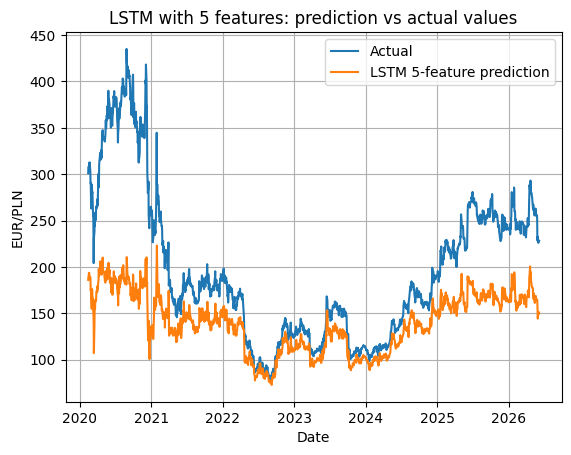

In [ ]:
multi_true, multi_pred, multi_mse, multi_mae = evaluate_regression_model(
    multi_lstm_model,
    X_test_multi,
    y_test_multi,
    scaler_y_feat,
    "LSTM 5-feature",
)

multi_test_dates = df_features["Date"].iloc[target_indices_multi[test_mask_multi]].values

plot_predictions(
    multi_test_dates,
    multi_true,
    multi_pred,
    "LSTM with 5 features: prediction vs actual values",
    "LSTM 5-feature prediction",
)

#PONOWNE PORÓWNANIE


,Model,MSE,MAE
0,SimpleRNN,1027.223170,19.589133
1,LSTM 1-feature,809.511609,19.104008
2,LSTM 5-feature,6122.281762,56.702219


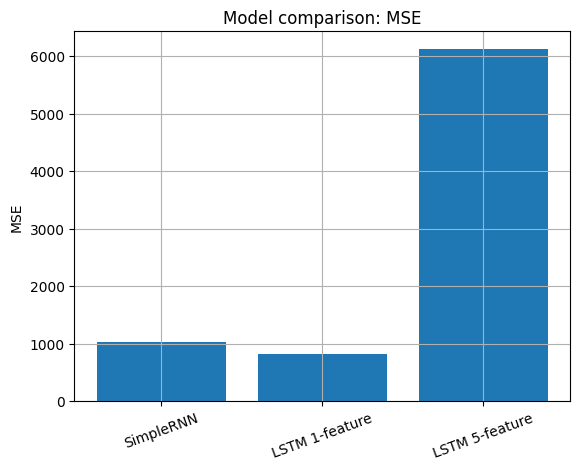

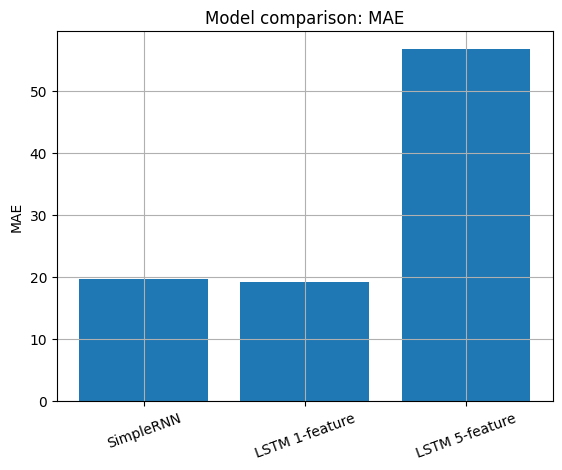

In [ ]:
results = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "MSE": simple_rnn_mse,
        "MAE": simple_rnn_mae,
    },
    {
        "Model": "LSTM 1-feature",
        "MSE": lstm_mse,
        "MAE": lstm_mae,
    },
    {
        "Model": "LSTM 5-feature",
        "MSE": multi_mse,
        "MAE": multi_mae,
    },
])

display(results)

plt.figure()
plt.bar(results["Model"], results["MSE"])
plt.title("Model comparison: MSE")
plt.ylabel("MSE")
plt.xticks(rotation=20)
plt.grid(True)
plt.show()

plt.figure()
plt.bar(results["Model"], results["MAE"])
plt.title("Model comparison: MAE")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.grid(True)
plt.show()


#6. Analiza i wnioski

Najlepsze wyniki uzyskał model LSTM wykorzystujący wyłącznie historyczne wartości kursu zamknięcia (LSTM 1-feature). Model ten osiągnął najniższe wartości błędów MSE oraz MAE, co oznacza najwyższą dokładność spośród wszystkich badanych modeli.

Na podstawie uzyskanych wyników za najlepszy model należy uznać model LSTM wykorzystujący jedynie historyczne wartości kursu zamknięcia. Osiągnął on najniższe wartości MSE i MAE oraz najlepiej odwzorowywał rzeczywisty przebieg kursu na danych testowych.